# 06 · Avaliação final, erros e limitações

**Objetivo.** Avaliar o modelo vigente como solução para o problema de negócio, e não só como vencedor da competição. Os notebooks 01 a 05 automatizam o ciclo. Este notebook responde às perguntas de quem vai usar o modelo:

1. Como são os dados e por que o problema é difícil?
2. O modelo é melhor do que alternativas triviais?
3. Que tipo de erro ele comete, com que frequência e em quais clientes?
4. Como escolher o limiar de decisão?
5. Quais são as limitações?

**Entradas.** Os lotes versionados em `data/raw/batches/` e o modelo vigente (`models/modelo_vigente.json`). O dataset é reconstruído com `pp.build_dataset`, que aplica as mesmas transformações do notebook 01. Por isso o notebook roda num clone novo, sem depender de `data/processed/`.

**Protocolo.** A partição treino/validação/teste é fixa por cliente (hash do ID). O teste usa **todos os lotes publicados**. O modelo vigente foi treinado só com o treino do `lote_001`, então nenhum cliente do teste participou do treino nem da seleção do modelo. O limiar é escolhido na **validação** e só depois aplicado ao teste.

**Saídas.** Figuras em `reports/figuras/` (usadas na apresentação) e `reports/evidencias/avaliacao_final.json`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config" / "config.yaml").is_file())
sys.path.insert(0, str(ROOT))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)

from src import ingestao, preprocessamento as pp
from src.promocao import load_active_model
from src.utils import load_config, write_json

pd.set_option("display.max_columns", 50)
cfg = load_config(ROOT)
TARGET = cfg["data"]["target"]
FIG = ROOT / "reports" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

RED, GRAY, SOFT = "#731B34", "#8A8F98", "#E7D3D9"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(FIG / name)))

bundle, manifest = load_active_model(cfg, ROOT)
FEATURES, model = bundle["features"], bundle["pipeline"]
dataset = pp.build_dataset(ingestao.load_released_batches(cfg, ROOT), cfg)

print("modelo vigente:", manifest["model_id"], "| treinado com", manifest["batches"])
print("atributos     :", FEATURES)
display(dataset.groupby(["lote", "particao"]).size().unstack())

modelo vigente: ciclo_20261116T223751Z_a2d3d2d2__random_forest | treinado com ['lote_001.csv']
atributos     : ['LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_AMT1', 'UTILIZACAO_MEDIA', 'MESES_EM_ATRASO', 'ATRASO_MAXIMO']


particao,teste,treino,validacao
lote,,,
lote_001,3536,10851,3613
lote_002,1170,3624,1206
lote_003,616,1764,620


## 1. Os dados

30.000 clientes de um banco de Taiwan (UCI, id 350). 27.000 estão nos três lotes publicados e 3.000 ficam separados, sem rótulo, para as previsões e a demonstração. Os pontos que mais influenciam a modelagem:

- **Desbalanceamento:** cerca de 22% dos clientes ficam inadimplentes. Um modelo que responde sempre "adimplente" acerta cerca de 78% e não serve para nada. Por isso a métrica primária é o F1 da classe inadimplente, e não a acurácia.
- **O histórico de pagamento domina:** a taxa de inadimplência sobe de forma abrupta com o atraso do último mês (`PAY_0`).

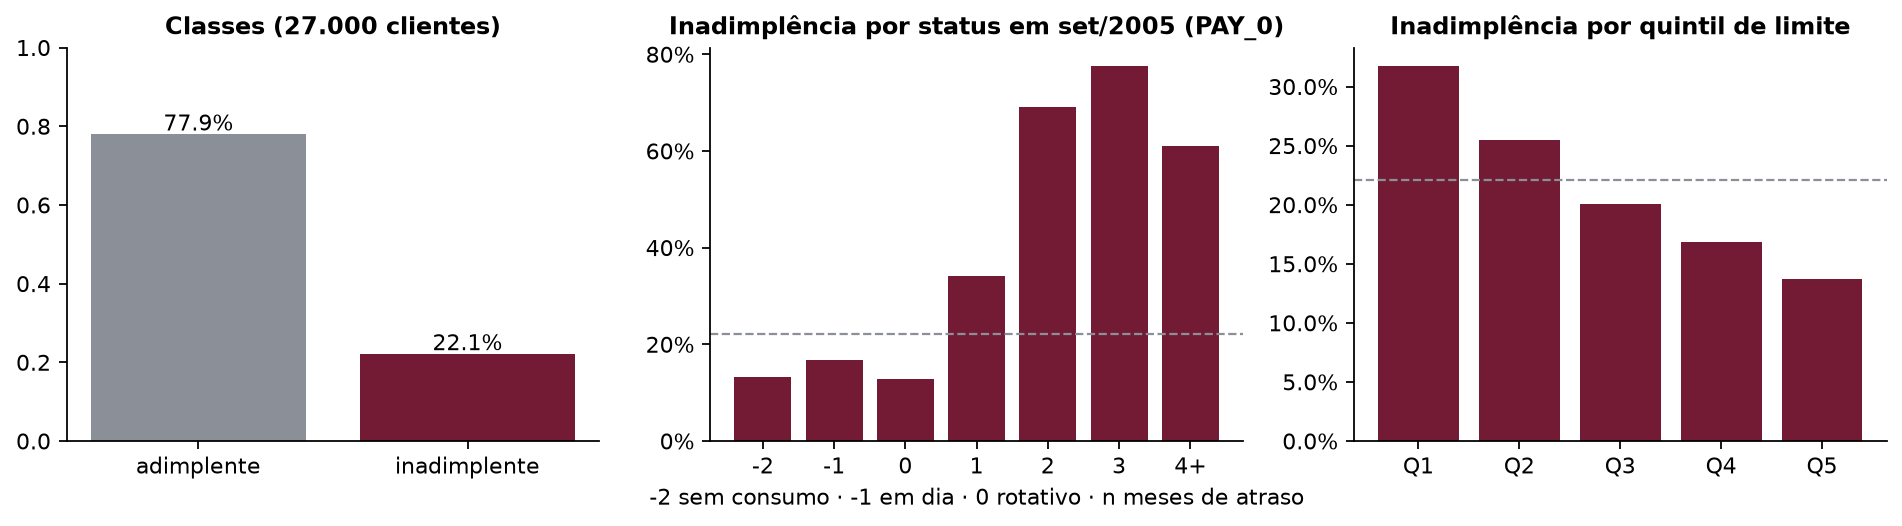

PAY_0,-2,-1,0,1,2,3,4
taxa,0.132,0.168,0.128,0.341,0.69,0.775,0.61
clientes,2478.000,5148.000,13257.000,3312.000,2393.00,289.000,123.00


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
rate = dataset[TARGET].mean()
axes[0].bar(["adimplente", "inadimplente"], [1 - rate, rate], color=[GRAY, RED])
for i, v in enumerate([1 - rate, rate]):
    axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center")
axes[0].set_title("Classes (27.000 clientes)")
axes[0].set_ylim(0, 1)

pay0 = dataset.assign(PAY_0=dataset.PAY_0.clip(upper=4)).groupby("PAY_0")[TARGET].agg(["mean", "size"])
axes[1].bar(pay0.index.astype(str).str.replace("4", "4+"), pay0["mean"], color=RED)
axes[1].axhline(rate, color=GRAY, ls="--", lw=1)
axes[1].set_title("Inadimplência por status em set/2005 (PAY_0)")
axes[1].set_xlabel("-2 sem consumo · -1 em dia · 0 rotativo · n meses de atraso")

lim = dataset.groupby(pd.qcut(dataset.LIMIT_BAL, 5))[TARGET].mean()
axes[2].bar([f"Q{i}" for i in range(1, 6)], lim.values, color=RED)
axes[2].axhline(rate, color=GRAY, ls="--", lw=1)
axes[2].set_title("Inadimplência por quintil de limite")
for ax in axes[1:]:
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
save(fig, "01_dados.png")
display(pay0.rename(columns={"mean": "taxa", "size": "clientes"}).round(3).T)

## 2. Desempenho no teste e comparação com alternativas simples

Três referências:

- **Sempre "adimplente"** (classe majoritária): mostra por que a acurácia engana.
- **Regra de negócio `PAY_0 ≥ 1`** (atrasou a fatura mais recente): é o que um analista faria sem modelo. O modelo só se justifica se superar essa regra.
- **Modelo vigente** no limiar padrão de 0,5.

In [3]:
test = dataset[dataset.particao == "teste"]
valid = dataset[dataset.particao == "validacao"]
y_test, s_test = test[TARGET].to_numpy(), model.predict_proba(test[FEATURES])[:, 1]
y_val, s_val = valid[TARGET].to_numpy(), model.predict_proba(valid[FEATURES])[:, 1]

def metrics(y, pred, score=None):
    out = {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
           "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0)}
    out["roc_auc"] = roc_auc_score(y, score) if score is not None else np.nan
    out["pr_auc"] = average_precision_score(y, score) if score is not None else np.nan
    return out

rule_test = (test.PAY_0 >= 1).astype(int).to_numpy()
comparison = pd.DataFrame({
    "sempre adimplente": metrics(y_test, np.zeros_like(y_test)),
    "regra PAY_0 >= 1": metrics(y_test, rule_test),
    "modelo vigente (limiar 0,5)": metrics(y_test, (s_test >= 0.5).astype(int), s_test),
}).T
print(f"teste: {len(test)} clientes, {y_test.mean():.1%} inadimplentes")
display(comparison.round(4))

teste: 5322 clientes, 21.3% inadimplentes


,accuracy,precision,recall,f1,roc_auc,pr_auc
sempre adimplente,0.7871,0.0000,0.0000,0.0000,NaN,NaN
regra PAY_0 >= 1,0.7794,0.4832,0.5216,0.5017,NaN,NaN
"modelo vigente (limiar 0,5)",0.7796,0.4862,0.6214,0.5455,0.7879,0.5445


## 3. Curvas ROC e precisão × revocação

A AUC-ROC mede se o modelo ordena bem os clientes por risco, independentemente do limiar. Com classes desbalanceadas, a curva precisão × revocação é mais informativa: a linha de base dela é a própria taxa de inadimplência, e não 0,5. O ponto marca a regra `PAY_0 ≥ 1`.

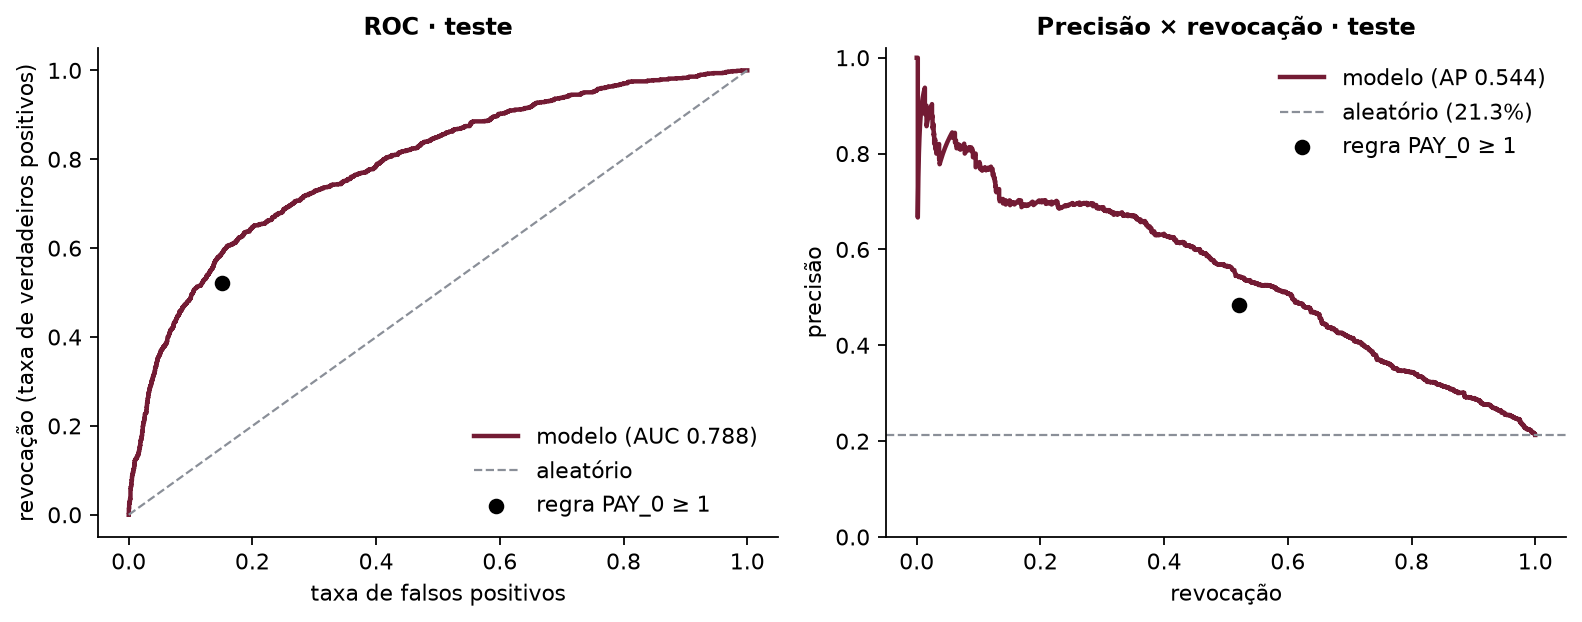

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y_test, s_test)
axes[0].plot(fpr, tpr, color=RED, lw=2, label=f"modelo (AUC {roc_auc_score(y_test, s_test):.3f})")
axes[0].plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="aleatório")
rule_fpr = ((rule_test == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
axes[0].scatter([rule_fpr], [recall_score(y_test, rule_test)], color="black", zorder=3, label="regra PAY_0 ≥ 1")
axes[0].set(xlabel="taxa de falsos positivos", ylabel="revocação (taxa de verdadeiros positivos)", title="ROC · teste")
axes[0].legend(loc="lower right", frameon=False)

prec, rec, _ = precision_recall_curve(y_test, s_test)
axes[1].plot(rec, prec, color=RED, lw=2, label=f"modelo (AP {average_precision_score(y_test, s_test):.3f})")
axes[1].axhline(y_test.mean(), color=GRAY, ls="--", lw=1, label=f"aleatório ({y_test.mean():.1%})")
axes[1].scatter([recall_score(y_test, rule_test)], [precision_score(y_test, rule_test)], color="black", zorder=3, label="regra PAY_0 ≥ 1")
axes[1].set(xlabel="revocação", ylabel="precisão", title="Precisão × revocação · teste", ylim=(0, 1.02))
axes[1].legend(loc="upper right", frameon=False)
save(fig, "02_roc_pr.png")

## 4. Escolha do limiar (na validação)

O modelo devolve uma pontuação, e a decisão depende de um limiar. Baixar o limiar encontra mais inadimplentes (revocação) ao custo de mais alarmes falsos (precisão). O limiar é escolhido **na validação**, maximizando o F1, e só então aplicado ao teste.

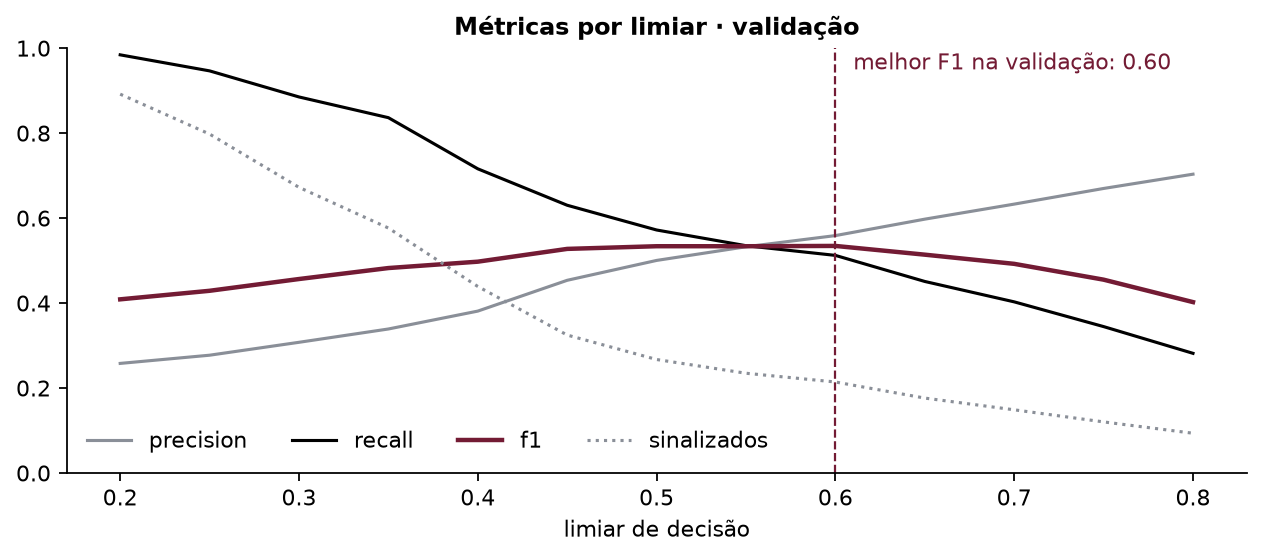

limiar escolhido na validação: 0.60


validação                               teste                          
       precision recall     f1 sinalizados precision recall     f1 sinalizados
limiar                                                                        
0.3        0.308  0.885  0.457       0.672     0.292  0.894  0.440       0.653
0.4        0.381  0.716  0.497       0.439     0.364  0.756  0.491       0.442
0.5        0.500  0.572  0.534       0.267     0.486  0.621  0.546       0.272
0.6        0.559  0.512  0.534       0.214     0.531  0.544  0.537       0.218
0.7        0.633  0.403  0.492       0.149     0.607  0.443  0.512       0.155

In [5]:
grid = np.round(np.arange(0.20, 0.81, 0.05), 2)
def sweep(y, s):
    return pd.DataFrame([{"limiar": t, "precision": precision_score(y, s >= t, zero_division=0),
                          "recall": recall_score(y, s >= t), "f1": f1_score(y, s >= t),
                          "sinalizados": float((s >= t).mean())} for t in grid]).set_index("limiar")

val_sweep, test_sweep = sweep(y_val, s_val), sweep(y_test, s_test)
best = float(val_sweep["f1"].idxmax())

fig, ax = plt.subplots(figsize=(8, 3.6))
for col, color, ls in [("precision", GRAY, "-"), ("recall", "black", "-"), ("f1", RED, "-"), ("sinalizados", GRAY, ":")]:
    ax.plot(val_sweep.index, val_sweep[col], color=color, ls=ls, lw=2 if col == "f1" else 1.4, label=col)
ax.axvline(best, color=RED, ls="--", lw=1)
ax.text(best + 0.01, 0.95, f"melhor F1 na validação: {best:.2f}", color=RED)
ax.set(xlabel="limiar de decisão", title="Métricas por limiar · validação", ylim=(0, 1))
ax.legend(frameon=False, ncol=4, loc="lower left")
save(fig, "03_limiar.png")

print(f"limiar escolhido na validação: {best:.2f}")
display(pd.concat({"validação": val_sweep, "teste": test_sweep}, axis=1).loc[[0.3, 0.4, 0.5, best, 0.7]].drop_duplicates().round(3))

## 5. Matriz de confusão e custo dos erros

Num banco os dois erros não custam o mesmo:

- **Falso negativo:** inadimplente classificado como bom pagador. É perda de crédito, o erro caro.
- **Falso positivo:** bom pagador sinalizado. Gera uma ação de cobrança ou análise desnecessária e algum atrito com o cliente.

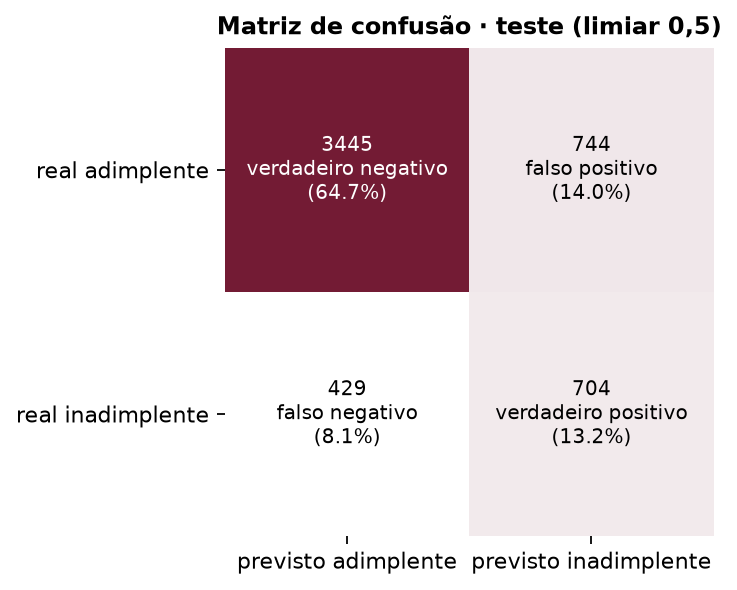

de 1133 inadimplentes, o modelo encontra 704 (62.1%) e deixa passar 429
de 1448 clientes sinalizados, 704 (48.6%) de fato ficam inadimplentes
regra PAY_0>=1 encontra 591 inadimplentes sinalizando 1223 clientes


In [6]:
pred_test = (s_test >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
fig, ax = plt.subplots(figsize=(4.6, 3.8))
cm = np.array([[tn, fp], [fn, tp]])
ax.imshow(cm, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("c", ["white", RED]))
labels = [["verdadeiro negativo", "falso positivo"], ["falso negativo", "verdadeiro positivo"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{labels[i][j]}\n({cm[i, j] / cm.sum():.1%})", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() * 0.6 else "black", fontsize=9)
ax.set_xticks([0, 1], ["previsto adimplente", "previsto inadimplente"])
ax.set_yticks([0, 1], ["real adimplente", "real inadimplente"])
ax.set_title("Matriz de confusão · teste (limiar 0,5)")
ax.spines[:].set_visible(False)
save(fig, "04_matriz_confusao.png")

print(f"de {tp + fn} inadimplentes, o modelo encontra {tp} ({tp / (tp + fn):.1%}) e deixa passar {fn}")
print(f"de {tp + fp} clientes sinalizados, {tp} ({tp / (tp + fp):.1%}) de fato ficam inadimplentes")
print(f"regra PAY_0>=1 encontra {((rule_test == 1) & (y_test == 1)).sum()} inadimplentes sinalizando {rule_test.sum()} clientes")

## 6. A pontuação não é uma probabilidade calibrada

Os modelos usam `class_weight="balanced"`, que dá mais peso aos inadimplentes no treino. Isso ajuda a revocação, mas desloca a pontuação para cima. A tabela abaixo compara, por decil de pontuação, a pontuação média com a taxa real de inadimplência. A pontuação **ordena bem** (a taxa real sobe a cada decil), mas não deve ser lida como "X% de chance".

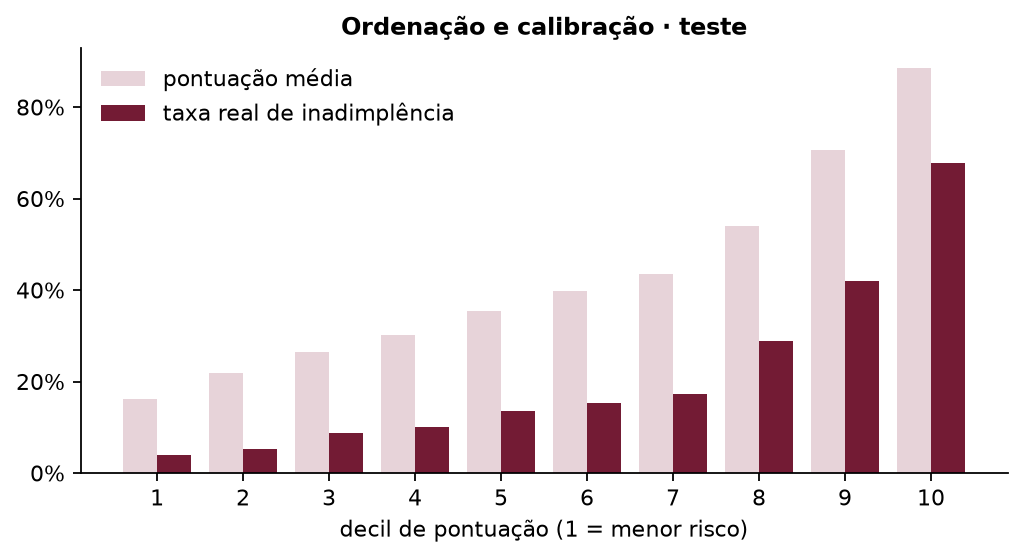

decil de maior risco: 67.7% de inadimplência (3.2x a média de 21.3%)


decil,1,2,3,4,5,6,7,8,9,10
pontuacao_media,0.161,0.218,0.264,0.302,0.354,0.397,0.436,0.541,0.706,0.885
taxa_real,0.039,0.053,0.088,0.102,0.135,0.152,0.173,0.289,0.419,0.677
clientes,533.000,532.000,532.000,532.000,532.000,532.000,532.000,532.000,532.000,533.000


In [7]:
deciles = pd.DataFrame({"score": s_test, "y": y_test}).assign(decil=lambda d: pd.qcut(d.score, 10, labels=range(1, 11)))
calib = deciles.groupby("decil", observed=True).agg(pontuacao_media=("score", "mean"), taxa_real=("y", "mean"), clientes=("y", "size"))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(1, 11)
ax.bar(x - 0.2, calib.pontuacao_media, width=0.4, color=SOFT, label="pontuação média")
ax.bar(x + 0.2, calib.taxa_real, width=0.4, color=RED, label="taxa real de inadimplência")
ax.set(xticks=x, xlabel="decil de pontuação (1 = menor risco)", title="Ordenação e calibração · teste")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False)
save(fig, "05_calibracao.png")
lift = calib.taxa_real.iloc[-1] / y_test.mean()
print(f"decil de maior risco: {calib.taxa_real.iloc[-1]:.1%} de inadimplência ({lift:.1f}x a média de {y_test.mean():.1%})")
display(calib.round(3).T)

## 7. Quais atributos o modelo usa

A importância por permutação embaralha um atributo de cada vez no teste e mede quanto a AUC cai. É agnóstica ao algoritmo e é calculada em dados que o modelo não viu.

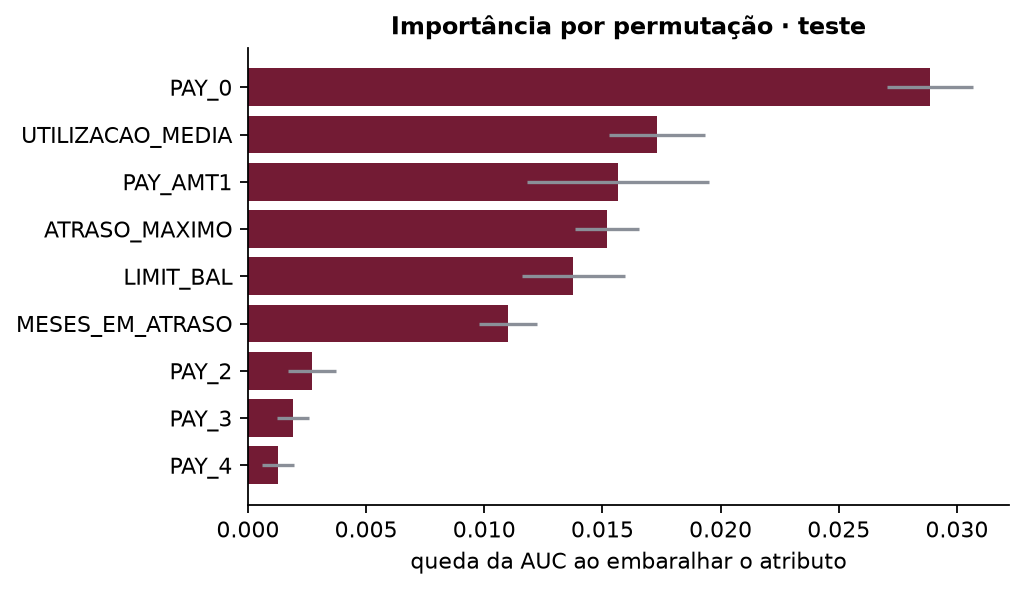

,PAY_0,UTILIZACAO_MEDIA,PAY_AMT1,ATRASO_MAXIMO,LIMIT_BAL,MESES_EM_ATRASO,PAY_2,PAY_3,PAY_4
queda_auc,0.0289,0.0173,0.0157,0.0152,0.0138,0.0110,0.0027,0.0019,0.0013
desvio,0.0018,0.0020,0.0038,0.0014,0.0022,0.0012,0.0010,0.0007,0.0007


In [8]:
imp = permutation_importance(model, test[FEATURES], y_test, scoring="roc_auc", n_repeats=10,
                             random_state=cfg["data"]["random_state"], n_jobs=-1)
importance = pd.DataFrame({"queda_auc": imp.importances_mean, "desvio": imp.importances_std}, index=FEATURES).sort_values("queda_auc")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(importance.index, importance.queda_auc, xerr=importance.desvio, color=RED, ecolor=GRAY)
ax.set(xlabel="queda da AUC ao embaralhar o atributo", title="Importância por permutação · teste")
save(fig, "06_importancia.png")
display(importance.sort_values("queda_auc", ascending=False).round(4).T)

## 8. Onde o modelo erra

O perfil mediano de cada célula da matriz de confusão e a taxa de erro por segmento mostram que os erros não são aleatórios.

In [9]:
cell = np.select([(y_test == 1) & (pred_test == 1), (y_test == 0) & (pred_test == 1), (y_test == 1) & (pred_test == 0)],
                 ["VP", "FP", "FN"], "VN")
errors = test.assign(celula=cell, pontuacao=s_test)
profile_cols = ["pontuacao", "PAY_0", "ATRASO_MAXIMO", "MESES_EM_ATRASO", "LIMIT_BAL", "UTILIZACAO_MEDIA", "PAY_AMT1", "AGE"]
display(errors.groupby("celula")[profile_cols].median().loc[["VP", "FN", "FP", "VN"]].round(3))

by_status = errors.assign(status=np.where(errors.PAY_0 >= 1, "atrasou em set/2005", "sem atraso em set/2005")).groupby("status").apply(
    lambda g: pd.Series({"clientes": len(g), "taxa_real": g[TARGET].mean(), "inadimplentes": int(g[TARGET].sum()),
                         "falsos_negativos": int((g.celula == "FN").sum()), "falsos_positivos": int((g.celula == "FP").sum())}),
    include_groups=False)
display(by_status.round(3))
share_fn = by_status.loc["sem atraso em set/2005", "falsos_negativos"] / by_status["falsos_negativos"].sum()
print(f"{share_fn:.0%} dos falsos negativos são clientes sem atraso no último mês")

,pontuacao,PAY_0,ATRASO_MAXIMO,MESES_EM_ATRASO,LIMIT_BAL,UTILIZACAO_MEDIA,PAY_AMT1,AGE
celula,,,,,,,,
VP,0.802,2.0,2.0,3.0,80000.0,0.562,1302.0,33.0
FN,0.374,0.0,0.0,0.0,130000.0,0.351,2211.0,35.0
FP,0.672,1.0,2.0,2.0,80000.0,0.273,390.0,33.0
VN,0.299,0.0,0.0,0.0,170000.0,0.236,3000.0,34.0


,clientes,taxa_real,inadimplentes,falsos_negativos,falsos_positivos
status,,,,,
atrasou em set/2005,1223.0,0.483,591.0,19.0,491.0
sem atraso em set/2005,4099.0,0.132,542.0,410.0,253.0


96% dos falsos negativos são clientes sem atraso no último mês


In [10]:
def group_rates(col, names):
    g = errors.groupby(col)
    return pd.DataFrame({"clientes": g.size(), "taxa_real": g[TARGET].mean(),
                         "revocação": g.apply(lambda d: recall_score(d[TARGET], d.celula.isin(["VP", "FP"]).astype(int), zero_division=0), include_groups=False),
                         "taxa_falso_positivo": g.apply(lambda d: ((d.celula == "FP").sum() / max((d[TARGET] == 0).sum(), 1)), include_groups=False)}
                        ).rename(index=names)

fairness = pd.concat({"SEX": group_rates("SEX", {1: "masculino", 2: "feminino"}),
                      "EDUCATION": group_rates("EDUCATION", {1: "pós-graduação", 2: "universidade", 3: "ensino médio", 4: "outros"}),
                      "faixa etária": group_rates(pd.cut(errors.AGE, [20, 30, 40, 50, 80], right=False), {})})
display(fairness.round(3))

clientes  taxa_real  revocação  \
SEX          masculino          2052      0.232      0.634   
             feminino           3270      0.201      0.612   
EDUCATION    pós-graduação      1881      0.191      0.583   
             universidade       2533      0.230      0.634   
             ensino médio        840      0.225      0.656   
             outros               68      0.029      0.500   
faixa etária [20, 30)           1714      0.222      0.668   
             [30, 40)           2012      0.190      0.579   
             [40, 50)           1096      0.221      0.595   
             [50, 80)            500      0.258      0.659   

                            taxa_falso_positivo  
SEX          masculino                    0.189  
             feminino                     0.171  
EDUCATION    pós-graduação                0.162  
             universidade                 0.171  
             ensino médio                 0.237  
             outros                       0.136  
faixa etária [20, 30)                     0.196  
             [30, 40)                     0.171  
             [40, 50)                     0.155  
             [50, 80)                     0.197

In [11]:
summary = {
    "model_id": manifest["model_id"], "n_teste": int(len(test)), "taxa_inadimplencia_teste": float(y_test.mean()),
    "comparacao_teste": comparison.round(4).to_dict(orient="index"),
    "limiar_escolhido_validacao": best,
    "teste_no_limiar_escolhido": test_sweep.loc[best].round(4).to_dict(),
    "matriz_confusao_teste_0_5": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "taxa_real_decil_maior_risco": float(calib.taxa_real.iloc[-1]),
    "importancia_permutacao_auc": importance.queda_auc.sort_values(ascending=False).round(4).to_dict(),
    "fracao_fn_sem_atraso_recente": float(share_fn),
}
write_json(ROOT / "reports" / "evidencias" / "avaliacao_final.json", summary)
summary

{'model_id': 'ciclo_20261116T223751Z_a2d3d2d2__random_forest',
 'n_teste': 5322,
 'taxa_inadimplencia_teste': 0.21288989101841413,
 'comparacao_teste': {'sempre adimplente': {'accuracy': 0.7871,
   'precision': 0.0,
   'recall': 0.0,
   'f1': 0.0,
   'roc_auc': nan,
   'pr_auc': nan},
  'regra PAY_0 >= 1': {'accuracy': 0.7794,
   'precision': 0.4832,
   'recall': 0.5216,
   'f1': 0.5017,
   'roc_auc': nan,
   'pr_auc': nan},
  'modelo vigente (limiar 0,5)': {'accuracy': 0.7796,
   'precision': 0.4862,
   'recall': 0.6214,
   'f1': 0.5455,
   'roc_auc': 0.7879,
   'pr_auc': 0.5445}},
 'limiar_escolhido_validacao': 0.6,
 'teste_no_limiar_escolhido': {'precision': 0.531,
  'recall': 0.5437,
  'f1': 0.5373,
  'sinalizados': 0.218},
 'matriz_confusao_teste_0_5': {'tn': 3445, 'fp': 744, 'fn': 429, 'tp': 704},
 'taxa_real_decil_maior_risco': 0.6772983114446529,
 'importancia_permutacao_auc': {'PAY_0': 0.0289,
  'UTILIZACAO_MEDIA': 0.0173,
  'PAY_AMT1': 0.0157,
  'ATRASO_MAXIMO': 0.0152,
  'LI

## Conclusões

Números do teste: 5.322 clientes que o modelo nunca viu, 21,3% inadimplentes.

**Interpretação.**
- **O modelo supera as alternativas simples.** Responder sempre "adimplente" dá 78,7% de acurácia e não encontra nenhum inadimplente. Por isso a acurácia não é a métrica certa aqui.
- **Frente à regra `PAY_0 ≥ 1`**, com precisão praticamente igual (48,6% contra 48,3%), o modelo encontra 62% dos inadimplentes, contra 52% da regra. São 704 contra 591 clientes, com F1 de 0,546 contra 0,502. Além disso, ele gera uma pontuação, o que permite escolher o ponto de operação. Uma regra fixa não permite isso.
- **A pontuação ordena bem o risco** (AUC-ROC 0,788). No decil de maior pontuação, 67,7% ficam inadimplentes, 3,2 vezes a média. No decil de menor pontuação, só 3,9%. O uso mais seguro do modelo é priorizar clientes para cobrança preventiva ou revisão de limite.
- **O que pesa mais é o atraso no último mês (`PAY_0`).** Em seguida vêm o uso do limite (`UTILIZACAO_MEDIA`), o valor pago (`PAY_AMT1`), o maior atraso do semestre e o limite de crédito. `PAY_2` a `PAY_4` acrescentam pouco, porque o que eles informam já está resumido em `ATRASO_MAXIMO` e `MESES_EM_ATRASO`.
- **O limiar é uma escolha de negócio.** Na validação, o F1 é praticamente o mesmo entre 0,5 e 0,6. O que muda é a troca entre precisão e revocação. Limiar 0,3: encontra 89% dos inadimplentes, mas sinaliza 65% da base. Limiar 0,7: 61% de precisão, com 44% de revocação.

**Erros.**
- **Os falsos negativos são o erro caro: 429 inadimplentes não detectados.** 96% deles não tinham atraso no último mês: são clientes "com cara de bom pagador", com pontuação mediana de 0,37. Com estes atributos, só dá para pegá-los baixando o limiar, o que multiplica os falsos positivos.
- **Os falsos positivos (744) são clientes que já tinham atrasado,** com mediana de 2 meses de atraso máximo, mas que pagaram no mês seguinte. É um erro mais barato: uma ação preventiva num cliente que pagaria.
- **Por grupo, a revocação é parecida entre os sexos** (63% contra 61%), e o modelo não usa `SEX`. Já a taxa de falso positivo de quem tem ensino médio (23,7%) é maior que a de pós-graduação (16,2%). Isso ocorre em parte porque a inadimplência real difere entre os grupos. Antes de qualquer uso real, isso precisa ser monitorado.

**Limitações.**
- **Contexto restrito.** São dados de 2005, de um único banco de Taiwan. O modelo não deve ser usado em outro contexto sem novo treino e nova validação.
- **Poucos atributos.** Só há seis meses de histórico e nenhuma informação de renda, emprego ou outras dívidas. Isso limita o teto de desempenho: o F1 fica em torno de 0,54, e os falsos negativos acima são, em boa parte, imprevisíveis com estes dados.
- **Pontuação não calibrada** (seção 6). Para lê-la como probabilidade, seria preciso calibrar, por exemplo com `CalibratedClassifierCV`.
- **Custos desconhecidos.** O dataset não informa o custo de um falso negativo nem o de um falso positivo. Sem isso, o limiar de 0,5 é uma escolha técnica, não de negócio.
- **Códigos não documentados.** Os códigos `PAY_x` = -2 e 0 e `EDUCATION` 0, 5 e 6 não constam do dicionário e foram interpretados ou agrupados. Outra interpretação poderia mudar o resultado.